CIS 360 - Spring 2026 - Assignment #3

Three practical applications of Generative Adversarial Networks:

1. Image generation - GANs can create realistic images based solely on text descriptions.
2. Text generation - GANs can create original text content, such as social media content or advertising.
3. Speech generation - GANs can create lifelike human sppech from text.

Three challenges facing Generative Adversarial Networks:

1. Mode collapse - the generator produces a limited, unrealistic variety of samples.
2. Training instability - when the updates of either the generator or the determinator dominate the training process, preventing the other from learning.
3. Vanishing gradients - the determinator becomes so effective it provides useless feedback to the generator.

In [1]:
#Import needed libraries
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import time
from IPython.display import Image

Architecture

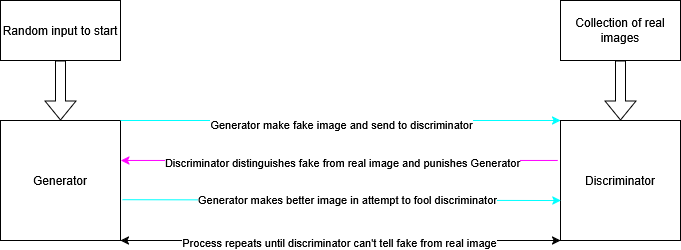

In [2]:
Image(filename='GAN.drawio.png') 

The code for the generator and discriminator is copied with some modifications from the file Week4_1_GAN_Generate_Syntethic_Image_Data_MNIST.ipynb

In [2]:
# This method returns a helper function to compute cross entropy loss
cross_entropy = tf.keras.losses.BinaryCrossentropy()

In [3]:
#Generator
LATENT_DIM = 128
def make_generator_model():
    generator = tf.keras.Sequential(
        [
            tf.keras.Input(shape=(LATENT_DIM,)),
            layers.Dense(8 * 8 * LATENT_DIM),
            layers.Reshape((8, 8, LATENT_DIM)),
            layers.Conv2DTranspose(LATENT_DIM, kernel_size=4, strides=2, padding="same"),
            layers.LeakyReLU(alpha=0.2),
            layers.Conv2DTranspose(LATENT_DIM * 2, kernel_size=4, strides=2, padding="same"),
            layers.LeakyReLU(alpha=0.2),
            layers.Conv2DTranspose(LATENT_DIM * 4, kernel_size=4, strides=2, padding="same"),
            layers.LeakyReLU(alpha=0.2),
            layers.Conv2D(3, kernel_size=5, padding="same", activation="sigmoid"),
        ],
    )
    return generator

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)

In [4]:
# Discriminator
DIM = 64
def make_discriminator_model():
    discriminator = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(DIM, DIM, 3)),
        layers.Conv2D(DIM, kernel_size=4, strides=2, padding="same"),
        layers.LeakyReLU(alpha=0.2),
        layers.Conv2D(DIM * 2, kernel_size=4, strides=2, padding="same"),
        layers.LeakyReLU(alpha=0.2),
        layers.Conv2D(DIM * 2, kernel_size=4, strides=2, padding="same"),
        layers.LeakyReLU(alpha=0.2),
        layers.Flatten(),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ])

    return discriminator

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

The CelebA Dataset

Unfortunately, due to the size of the database and the relatively lack of computational power of my computer, I was only able to load 10 batches (320 images). I attempted to use Google Colab due to its much greated computational power, but my Internet connection is too slow to upload the large number of images needed by the discriminator.

In [ ]:
PATH = 'img_align_celeba/img_align_celeba' #feel free to change this to a different directory of images
# take(10) will take only 10 batches
train_dataset = tf.keras.utils.image_dataset_from_directory(
    PATH,
    image_size=(DIM, DIM),
    batch_size=32,
    labels=None,
    label_mode=None
).take(10).map(lambda x: (x - 127.5) / 127.5) # normalization
# shuffle then batch the data
train_dataset = train_dataset.shuffle(buffer_size=320)
print(len(train_dataset))

Found 202599 files.
10


The training code

C:\Users\hsfer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


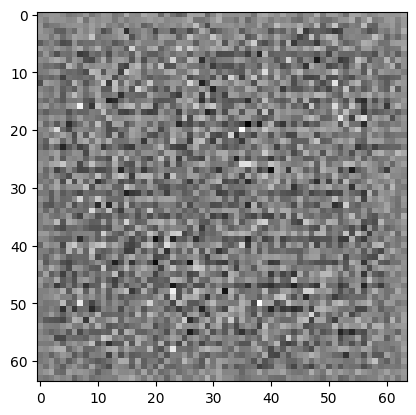

In [ ]:
generator = make_generator_model()  # Create generator
noise = tf.random.normal([1, LATENT_DIM])
generated_image = generator(noise, training=False) # Generate random image
plt.imshow(generated_image[0, :, :, 0], cmap='gray') # Show random image

In [ ]:
discriminator = make_discriminator_model() # Create discriminator
decision = discriminator(generated_image)
print (decision)

tf.Tensor([[0.5194886]], shape=(1, 1), dtype=float32)


Due to the lack of computational power, I was only able to run 10 epochs.

The code below is copied with some modifications from the file Week4_1_GAN_Generate_Syntethic_Image_Data_MNIST.ipynb

In [ ]:
EPOCHS = 10 
NOISE_DIM = 128
BATCH_SIZE = 256
seed = tf.random.normal([16, NOISE_DIM])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
      generated_images = generator(noise, training=True)

      real_output = discriminator(images, training=True)
      fake_output = discriminator(generated_images, training=True)

      gen_loss = generator_loss(fake_output)
      disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

def generate_and_save_images(model, test_input):
  predictions = model(test_input, training=False)

  fig = plt.figure(figsize=(4, 4))

  for i in range(predictions.shape[0]):
      plt.subplot(4, 4, i+1)
      plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
      plt.axis('off')

  plt.show()

def train(dataset, epochs):
  for epoch in range(epochs):
    start = time.time()

    for image_batch in dataset:
      train_step(image_batch)

    generate_and_save_images(generator,seed)
    print ('Time for epoch {} is {} sec'.format(epoch + 1, time.time()-start))

  # Generate after the final epoch
  generate_and_save_images(generator,seed)

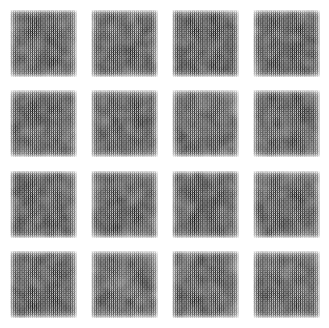

Time for epoch 1 is 176.17980909347534 sec


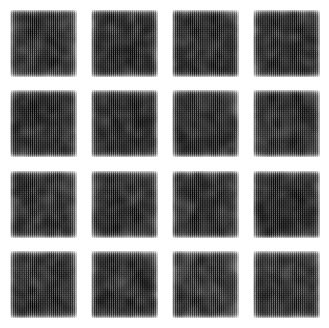

Time for epoch 2 is 190.7856523990631 sec


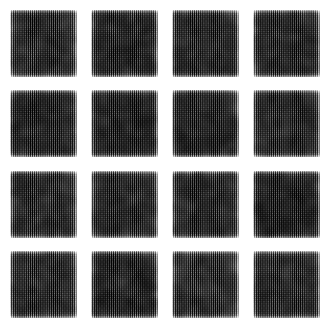

Time for epoch 3 is 189.36783361434937 sec


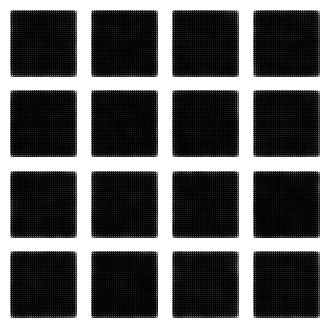

Time for epoch 4 is 202.73977637290955 sec


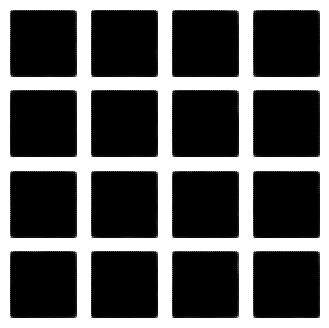

Time for epoch 5 is 215.88587737083435 sec


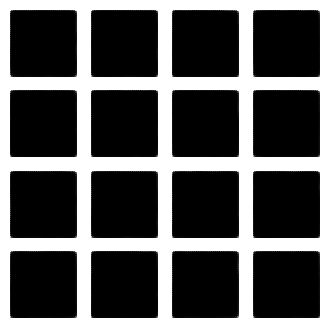

Time for epoch 6 is 198.42823386192322 sec


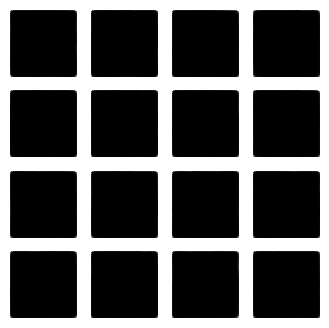

Time for epoch 7 is 206.40125942230225 sec


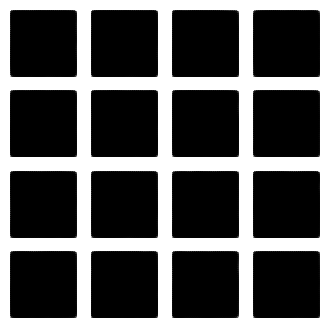

Time for epoch 8 is 204.3279595375061 sec


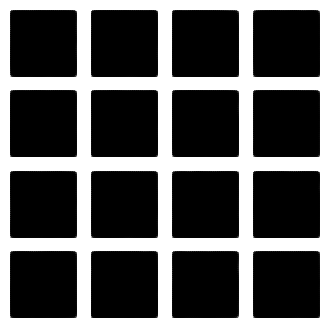

Time for epoch 9 is 190.74268698692322 sec


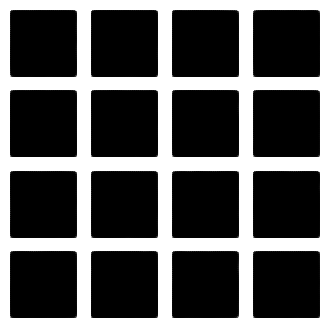

Time for epoch 10 is 196.47658133506775 sec


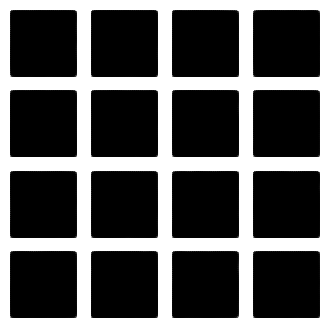

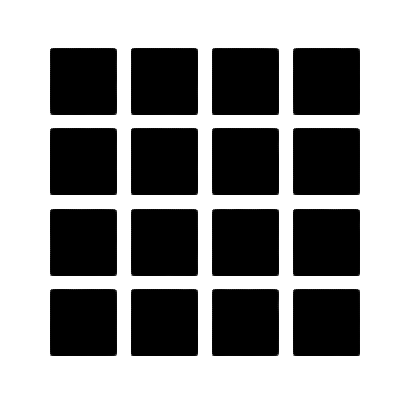

In [ ]:
# Run GAN
train(train_dataset, EPOCHS)

There is no single objective metric or function for the evaluation of GANs. Therefore, a subjective evaluation will be used. Unfortunately, the limited number of real images available to the discriminator and the limited number of training epochs makes even subjective evaluation difficult. As can be seen from the images above, the generated images did become less random for each epoch. Beyond that, no real conclusions can be drawn.